In [65]:
import cv2
import numpy as np

image = cv2.imread("astronaut_gray.png", cv2.IMREAD_GRAYSCALE)

print(image.shape)
print(image.size)
print(type(image))
print(image.min())
print(image.max())

print(f"Width: {image.shape[1]}px, Height: {image.shape[0]}px")

(384, 512)
196608
<class 'numpy.ndarray'>
0
255
Width: 512px, Height: 384px


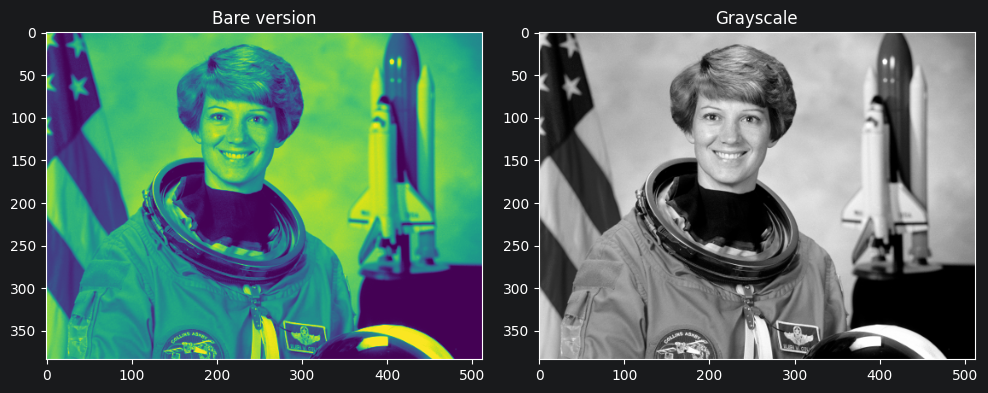

The bare version uses the default `viridis` colour map from MatPlotLib, which transitions from purple to yellow


In [75]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.imshow(image)
ax1.set_title("Bare version")

ax2.imshow(image, cmap="gray", vmin=0, vmax=255)
ax2.set_title("Grayscale")

plt.tight_layout()
plt.show()

print(
        "The bare version uses the default `viridis` colour map from MatPlotLib, which transitions from purple to yellow")


In [67]:
print(f"Value of numpy index `img[100, 200]`: {image[100, 200]}")
print(f"OpenCV index `(50, 300)`: {image[300, 50]}")

Value of numpy index `img[100, 200]`: 60
OpenCV index `(50, 300)`: 145


In [68]:
brightest_px = np.argmax(image)
brightest_row, brightest_col = np.unravel_index(brightest_px, image.shape)

print(f"(row, col) = ({brightest_row}, {brightest_col})")
print(f"(x, y) = ({brightest_col}, {brightest_row})")

print(
        "`np.argmax` returns the first occurrence of the maximum value, which in a row-order system will be this position")

(row, col) = (34, 403)
(x, y) = (403, 34)
`np.argmax` returns the first occurrence of the maximum value, which in a row-order system will be this position


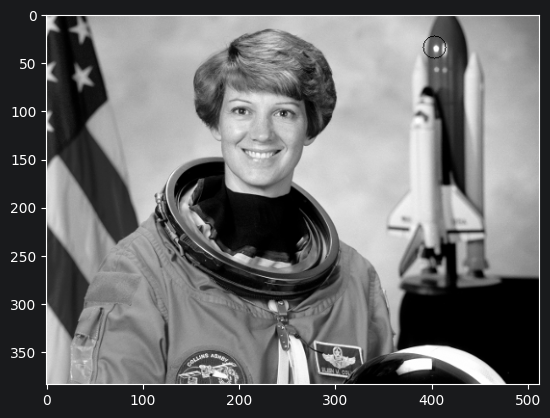

In [69]:
image_copy = image.copy()
cv2.circle(image_copy, (brightest_col, brightest_row), 12, (0, 0, 0))

plt.imshow(image_copy, cmap="gray")

Cropped image shape: (161, 151)


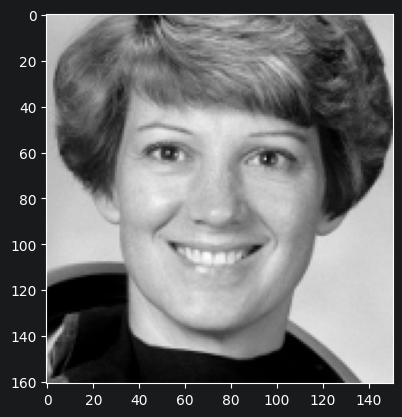

In [70]:
image_cropped = image[40:201, 150:301]

print(f"Cropped image shape: {image_cropped.shape}")
plt.imshow(image_cropped, cmap="gray")


In [71]:
img_ver_flipped_man = image.copy()[::-1]
is_equal_flip_ver = np.array_equal(img_ver_flipped_man, cv2.flip(image.copy(), 0))
print(f"Vertical flip successful: {is_equal_flip_ver}")

img_hor_flipped_man = np.fliplr(image.copy())
is_equal_flip_hor = np.array_equal(img_hor_flipped_man, cv2.flip(image.copy(), 1))
print(f"Horizontal flip successful: {is_equal_flip_hor}")

Vertical flip successful: True
Horizontal flip successful: True


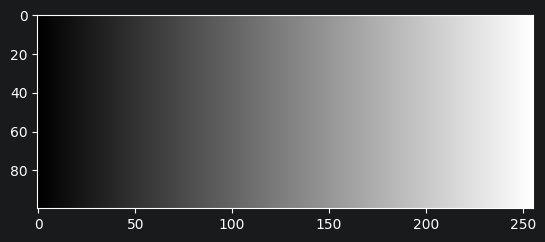

In [74]:
# LTR Gradient

grayscale_arange = np.arange(256)

ltr_image = np.tile(grayscale_arange, (100, 1))
plt.imshow(ltr_image, cmap="gray")

Text(0.5, 1.0, 'Rectangle with cv2')

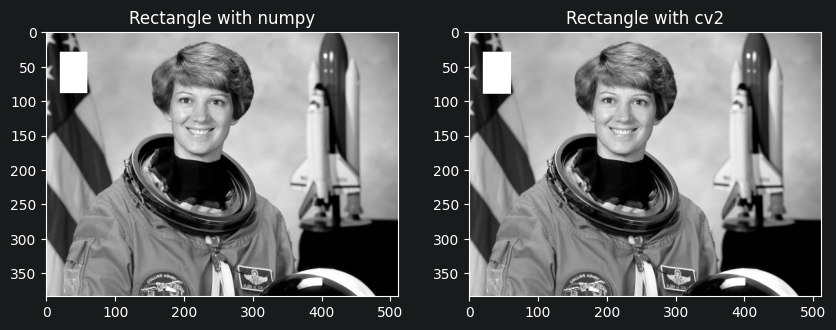

In [94]:
cv2_rect_img = image.copy()
np_rect_img = image.copy()

np_rect_img[30:90, 20:60] = 255
cv2.rectangle(cv2_rect_img, (20, 30), (60, 90), 255, -1)

fig, (npx, cvx) = plt.subplots(1, 2, figsize=(10, 5))
npx.imshow(np_rect_img, cmap="gray")
npx.set_title("Rectangle with numpy")

cvx.imshow(cv2_rect_img, cmap="gray")
cvx.set_title("Rectangle with cv2")